# Predicción de las fluctuaciones del precio del arroz en Ibarra mediante Machine Learning

**Universidad:** Yachay Tech  
**Programa:** Maestría en Ciencia de Datos

## Objetivo general
Desarrollar y comparar modelos de aprendizaje automático para predecir el precio mensual del arroz comercializado en Ibarra, utilizando información histórica de precios de comercialización y precios al productor.

## Período de estudio
Agosto de 2022 a julio de 2026.

## Metodología
Integración de datos, ingeniería de características, aprendizaje automático supervisado, validación temporal y evaluación de predicciones.

In [52]:

# Importamos las librerías necesarias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [53]:
# Cargamos los archivos CSV desde la computadora

archivos = files.upload()

Saving arroz_ibarra_limpio.csv to arroz_ibarra_limpio (2).csv
Saving arroz_productor_limpio.csv to arroz_productor_limpio (2).csv


In [54]:
# Leemos los archivos CSV con pandas

ibarra = pd.read_csv("arroz_ibarra_limpio.csv")
productor = pd.read_csv("arroz_productor_limpio.csv")

# Comprobamos sus dimensiones

print("Datos de Ibarra:", ibarra.shape)
print("Datos del productor:", productor.shape)

Datos de Ibarra: (61, 14)
Datos del productor: (184, 12)


In [55]:
# Visualizamos las primeras cinco filas de Ibarra

ibarra.head()

,Año,Mes,Mercado,Provincia,Cantón,Producto,Pres.,Cant.,Uni. Med.,Precio Promedio (USD),Precio Promedio (USD/Kg),Producto_limpio,Mes_num,Fecha
0,2012,Enero,Ibarra - Bodegas,Imbabura,Ibarra,Arroz Pilado natural grano largo,Quintal,100.0,Libra,43.166667,0.942222,arroz pilado natural grano largo,1,2012-01-01
1,2012,Febrero,Ibarra - Bodegas,Imbabura,Ibarra,Arroz Pilado natural grano largo,Quintal,100.0,Libra,44.200000,0.968750,arroz pilado natural grano largo,2,2012-02-01
2,2012,Marzo,Ibarra - Bodegas,Imbabura,Ibarra,Arroz Pilado natural grano largo,Quintal,100.0,Libra,44.466667,0.973333,arroz pilado natural grano largo,3,2012-03-01
3,2012,Abril,Ibarra - Bodegas,Imbabura,Ibarra,Arroz Pilado natural grano largo,Quintal,100.0,Libra,45.133333,0.992222,arroz pilado natural grano largo,4,2012-04-01
4,2012,Mayo,Ibarra - Bodegas,Imbabura,Ibarra,Arroz Pilado natural grano largo,Quintal,100.0,Libra,45.066667,0.990000,arroz pilado natural grano largo,5,2012-05-01


In [56]:
# Revisamos las columnas de nuestros archivos

print("COLUMNAS DE IBARRA:")
print(ibarra.columns.tolist())

print("\nCOLUMNAS DEL PRODUCTOR:")
print(productor.columns.tolist())


COLUMNAS DE IBARRA:
['Año', 'Mes', 'Mercado', 'Provincia', 'Cantón', 'Producto', 'Pres.', 'Cant.', 'Uni. Med.', 'Precio Promedio (USD)', 'Precio  Promedio (USD/Kg)', 'Producto_limpio', 'Mes_num', 'Fecha']

COLUMNAS DEL PRODUCTOR:
['Año', 'Mes', 'Provincia', 'Producto', 'Presentación', 'Equivalencia', 'Unidad De Medida', 'Precio Promedio (USD)', 'Precio Promedio (USD/KG)', 'Producto_limpio', 'Mes_num', 'Fecha']


In [57]:
# PASO 7: Seleccionar el período de estudio

# Convertimos la columna Fecha en formato de fecha
ibarra["Fecha"] = pd.to_datetime(ibarra["Fecha"])
productor["Fecha"] = pd.to_datetime(productor["Fecha"])

# Definimos el período de nuestra investigación
fecha_inicio = "2022-08-01"
fecha_fin = "2026-07-31"

# Filtramos los registros del período seleccionado
ibarra_filtrado = ibarra[
    (ibarra["Fecha"] >= fecha_inicio) &
    (ibarra["Fecha"] <= fecha_fin)
].copy()

productor_filtrado = productor[
    (productor["Fecha"] >= fecha_inicio) &
    (productor["Fecha"] <= fecha_fin)
].copy()

# Mostramos los resultados
print("Registros de Ibarra:", len(ibarra_filtrado))
print("Registros del productor:", len(productor_filtrado))

print("\nPeríodo de Ibarra:")
print(ibarra_filtrado["Fecha"].min())
print(ibarra_filtrado["Fecha"].max())

Registros de Ibarra: 49
Registros del productor: 116

Período de Ibarra:
2022-08-01 00:00:00
2026-07-01 00:00:00


In [58]:
# PASO 8: Corregimos los nombres de columnas

# Eliminamos espacios adicionales
ibarra_filtrado.columns = (
    ibarra_filtrado.columns.str.strip()
)

# Identificamos la columna del precio
columna_precio = [
    columna for columna in ibarra_filtrado.columns
    if "Precio" in columna
    and "USD/Kg" in columna
][0]

# Mostramos los registros repetidos
print("REGISTROS DE AGOSTO DE 2022:")

display(
    ibarra_filtrado[
        ibarra_filtrado["Fecha"] == "2022-08-01"
    ][["Fecha", "Producto", columna_precio]]
)


REGISTROS DE AGOSTO DE 2022:


,Fecha,Producto,Precio Promedio (USD/Kg)
12,2022-08-01,Arroz Pilado Natural Grano Largo,1.05
13,2022-08-01,Arroz Pilado Natural Grano Largo,0.92


In [59]:
# PASO 9: Examinar los dos registros de agosto de 2022

agosto_2022 = ibarra_filtrado[
    ibarra_filtrado["Fecha"] == "2022-08-01"
]

# Mostramos todas las columnas de ambos registros
display(agosto_2022.T)


,12,13
Año,2022,2022
Mes,Agosto,Agosto
Mercado,Ibarra - Bodegas,Ibarra - Bodegas
Provincia,Imbabura,Imbabura
Cantón,Ibarra,Ibarra
Producto,Arroz Pilado Natural Grano Largo,Arroz Pilado Natural Grano Largo
Pres.,Quintal,Quintal
Cant.,100.0,100.0
Uni. Med.,Libra,Libra
Precio Promedio (USD),48.0,42.0


In [60]:
# PASO 10: Consolidar los precios mensuales de Ibarra

# Calculamos el precio promedio por mes
ibarra_mensual = (
    ibarra_filtrado
    .groupby("Fecha", as_index=False)
    .agg(
        Precio_Ibarra=(columna_precio, "mean")
    )
    .sort_values("Fecha")
)

# Comprobamos los resultados
print("Cantidad de meses:", len(ibarra_mensual))

print("\nPrimeros cinco meses:")
display(ibarra_mensual.head())

print("\nÚltimos cinco meses:")
display(ibarra_mensual.tail())

print("\nFechas repetidas:",
      ibarra_mensual["Fecha"].duplicated().sum())


Cantidad de meses: 48

Primeros cinco meses:


,Fecha,Precio_Ibarra
0,2022-08-01,0.985
1,2022-09-01,1.050
2,2022-10-01,1.050
3,2022-11-01,1.050
4,2022-12-01,1.050



Últimos cinco meses:


,Fecha,Precio_Ibarra
43,2026-03-01,1.330000
44,2026-04-01,1.300000
45,2026-05-01,1.300000
46,2026-06-01,1.293333
47,2026-07-01,1.258750



Fechas repetidas: 0


## Paso 11. Preparación de precios al productor

Se organizan los precios históricos al productor por provincia y mes, con el propósito de integrarlos posteriormente con la serie mensual de precios del arroz en Ibarra. Esta transformación permitirá evaluar si los precios al productor de meses anteriores contienen información útil para la predicción.

In [61]:
# PASO 11.1: Verificar columnas del productor

print("COLUMNAS DEL ARCHIVO PRODUCTOR:")

for columna in productor_filtrado.columns:
    print(repr(columna))


COLUMNAS DEL ARCHIVO PRODUCTOR:
'Año'
'Mes'
'Provincia'
'Producto'
'Presentación'
'Equivalencia'
'Unidad De Medida'
'Precio Promedio (USD)'
'Precio Promedio (USD/KG)'
'Producto_limpio'
'Mes_num'
'Fecha'


In [62]:
# PASO 11.2: Analizar los registros del productor

# Identificamos la columna correcta
columna_precio_productor = "Precio Promedio (USD/KG)"

# Revisamos cuántos registros tiene cada provincia
print("REGISTROS POR PROVINCIA:")
print(productor_filtrado["Provincia"].value_counts())

# Verificamos si hay registros repetidos
# para una misma provincia y mes
conteo_productor = (
    productor_filtrado
    .groupby(["Fecha", "Provincia"])
    .size()
    .reset_index(name="Cantidad_Registros")
)

print("\nMESES CON MÁS DE UN REGISTRO:")
display(
    conteo_productor[
        conteo_productor["Cantidad_Registros"] > 1
    ]
)


REGISTROS POR PROVINCIA:
Provincia
EL ORO    48
LOJA      44
MANABÍ    24
Name: count, dtype: int64

MESES CON MÁS DE UN REGISTRO:


,Fecha,Provincia,Cantidad_Registros


## Paso 12. Integración de las series temporales

Se integran los precios mensuales del arroz comercializado en Ibarra con los precios al productor de El Oro, Loja y Manabí, utilizando la fecha como clave común.

El objetivo es construir un conjunto de datos que permita evaluar posteriormente si los precios históricos al productor aportan información útil para predecir las fluctuaciones del precio del arroz en Ibarra.

In [63]:
# PASO 12: Integrar los precios del arroz

# Organizamos los precios al productor por provincia
productor_mensual = productor_filtrado.pivot(
    index="Fecha",
    columns="Provincia",
    values=columna_precio_productor
)

# Asignamos nombres claros a las columnas
productor_mensual = productor_mensual.rename(
    columns={
        "EL ORO": "Precio_El_Oro",
        "LOJA": "Precio_Loja",
        "MANABÍ": "Precio_Manabi"
    }
).reset_index()

# Unimos los datos utilizando la fecha
base_integrada = pd.merge(
    ibarra_mensual,
    productor_mensual,
    on="Fecha",
    how="left",
    validate="one_to_one"
)

# Ordenamos cronológicamente
base_integrada = (
    base_integrada
    .sort_values("Fecha")
    .reset_index(drop=True)
)

# Mostramos los resultados
print("DIMENSIONES DE LA BASE INTEGRADA:")
print(base_integrada.shape)

print("\nPRIMEROS CINCO REGISTROS:")
display(base_integrada.head())

print("\nVALORES FALTANTES POR COLUMNA:")
print(base_integrada.isna().sum())


DIMENSIONES DE LA BASE INTEGRADA:
(48, 5)

PRIMEROS CINCO REGISTROS:


,Fecha,Precio_Ibarra,Precio_El_Oro,Precio_Loja,Precio_Manabi
0,2022-08-01,0.985,0.662489,0.678289,NaN
1,2022-09-01,1.050,0.667266,0.682331,NaN
2,2022-10-01,1.050,0.654497,0.646943,0.650364
3,2022-11-01,1.050,0.667188,0.661387,0.604696
4,2022-12-01,1.050,0.659383,0.650364,0.614845



VALORES FALTANTES POR COLUMNA:
Fecha             0
Precio_Ibarra     0
Precio_El_Oro     0
Precio_Loja       4
Precio_Manabi    24
dtype: int64


## Paso 13. Ingeniería de características para Machine Learning

Se construyen variables predictoras a partir de los precios históricos del arroz en Ibarra y El Oro. Se utilizan precios actuales y rezagos de meses anteriores para estimar el precio del mes siguiente.

La variable objetivo será el precio del arroz en Ibarra del mes siguiente. Este procedimiento permite formular un problema de regresión supervisada respetando el orden cronológico de los datos.
 Copiar texto

In [64]:
# PASO 13: Ingeniería de características

# Creamos una copia de las variables que utilizaremos
datos_ml = base_integrada[
    ["Fecha", "Precio_Ibarra", "Precio_El_Oro"]
].copy()

# Verificamos el orden cronológico
datos_ml = datos_ml.sort_values("Fecha")

# Creamos variables con precios de meses anteriores
datos_ml["Ibarra_mes_anterior"] = (
    datos_ml["Precio_Ibarra"].shift(1)
)

datos_ml["Ibarra_dos_meses"] = (
    datos_ml["Precio_Ibarra"].shift(2)
)

datos_ml["El_Oro_mes_anterior"] = (
    datos_ml["Precio_El_Oro"].shift(1)
)

# Creamos la variable que queremos predecir:
# el precio de Ibarra del siguiente mes
datos_ml["Precio_siguiente_mes"] = (
    datos_ml["Precio_Ibarra"].shift(-1)
)

# Eliminamos las filas incompletas generadas por los rezagos
datos_ml = datos_ml.dropna().reset_index(drop=True)

print("DIMENSIONES DE LOS DATOS PARA MACHINE LEARNING:")
print(datos_ml.shape)

print("\nPRIMEROS CINCO REGISTROS:")
display(datos_ml.head())

print("\nÚLTIMOS CINCO REGISTROS:")
display(datos_ml.tail())


DIMENSIONES DE LOS DATOS PARA MACHINE LEARNING:
(45, 7)

PRIMEROS CINCO REGISTROS:


,Fecha,Precio_Ibarra,Precio_El_Oro,Ibarra_mes_anterior,Ibarra_dos_meses,El_Oro_mes_anterior,Precio_siguiente_mes
0,2022-10-01,1.050000,0.654497,1.05,0.985,0.667266,1.050000
1,2022-11-01,1.050000,0.667188,1.05,1.050,0.654497,1.050000
2,2022-12-01,1.050000,0.659383,1.05,1.050,0.667188,1.050000
3,2023-01-01,1.050000,0.637136,1.05,1.050,0.659383,1.038571
4,2023-02-01,1.038571,0.629320,1.05,1.050,0.637136,1.010000



ÚLTIMOS CINCO REGISTROS:


,Fecha,Precio_Ibarra,Precio_El_Oro,Ibarra_mes_anterior,Ibarra_dos_meses,El_Oro_mes_anterior,Precio_siguiente_mes
40,2026-02-01,1.347143,0.496040,1.371250,1.383750,0.534088,1.330000
41,2026-03-01,1.330000,0.479505,1.347143,1.371250,0.496040,1.300000
42,2026-04-01,1.300000,0.462971,1.330000,1.347143,0.479505,1.300000
43,2026-05-01,1.300000,0.462971,1.300000,1.330000,0.462971,1.293333
44,2026-06-01,1.293333,0.449404,1.300000,1.300000,0.462971,1.258750


## Paso 14. División cronológica de entrenamiento y prueba

Se divide el conjunto de datos respetando el orden temporal para evitar utilizar información futura durante el entrenamiento. Los primeros 36 registros se destinan al entrenamiento y los últimos 9 a la evaluación del desempeño predictivo.

Se compararán modelos basados únicamente en precios históricos de Ibarra con modelos que también incorporan precios al productor de El Oro.
 Copiar texto

In [65]:
# PASO 14: División cronológica de los datos

# Primeros 36 registros para entrenamiento
train = datos_ml.iloc[:36].copy()

# Últimos 9 registros para prueba
test = datos_ml.iloc[36:].copy()

# Variables del modelo A: solo precios de Ibarra
variables_A = [
    "Precio_Ibarra",
    "Ibarra_mes_anterior",
    "Ibarra_dos_meses"
]

# Variables del modelo B: Ibarra y productor El Oro
variables_B = [
    "Precio_Ibarra",
    "Ibarra_mes_anterior",
    "Ibarra_dos_meses",
    "Precio_El_Oro",
    "El_Oro_mes_anterior"
]

# Variable objetivo
objetivo = "Precio_siguiente_mes"

# Preparamos las matrices de entrenamiento y prueba
X_train_A = train[variables_A]
X_test_A = test[variables_A]

X_train_B = train[variables_B]
X_test_B = test[variables_B]

y_train = train[objetivo]
y_test = test[objetivo]

# Comprobamos la división
print("Registros de entrenamiento:", len(train))
print("Registros de prueba:", len(test))

print("\nEntrenamiento:")
print(train["Fecha"].min(), "hasta", train["Fecha"].max())

print("\nPrueba:")
print(test["Fecha"].min(), "hasta", test["Fecha"].max())

print("\nVariables del modelo A:", variables_A)
print("Variables del modelo B:", variables_B)


Registros de entrenamiento: 36
Registros de prueba: 9

Entrenamiento:
2022-10-01 00:00:00 hasta 2025-09-01 00:00:00

Prueba:
2025-10-01 00:00:00 hasta 2026-06-01 00:00:00

Variables del modelo A: ['Precio_Ibarra', 'Ibarra_mes_anterior', 'Ibarra_dos_meses']
Variables del modelo B: ['Precio_Ibarra', 'Ibarra_mes_anterior', 'Ibarra_dos_meses', 'Precio_El_Oro', 'El_Oro_mes_anterior']


##Paso 15. Evolución histórica de los precios del arroz

Se presenta la evolución mensual del precio del arroz comercializado en Ibarra y del precio al productor en El Oro entre agosto de 2022 y julio de 2026.

Esta visualización permite comparar el comportamiento de ambas series e identificar posibles diferencias y fluctuaciones antes del entrenamiento de los modelos de aprendizaje automático.

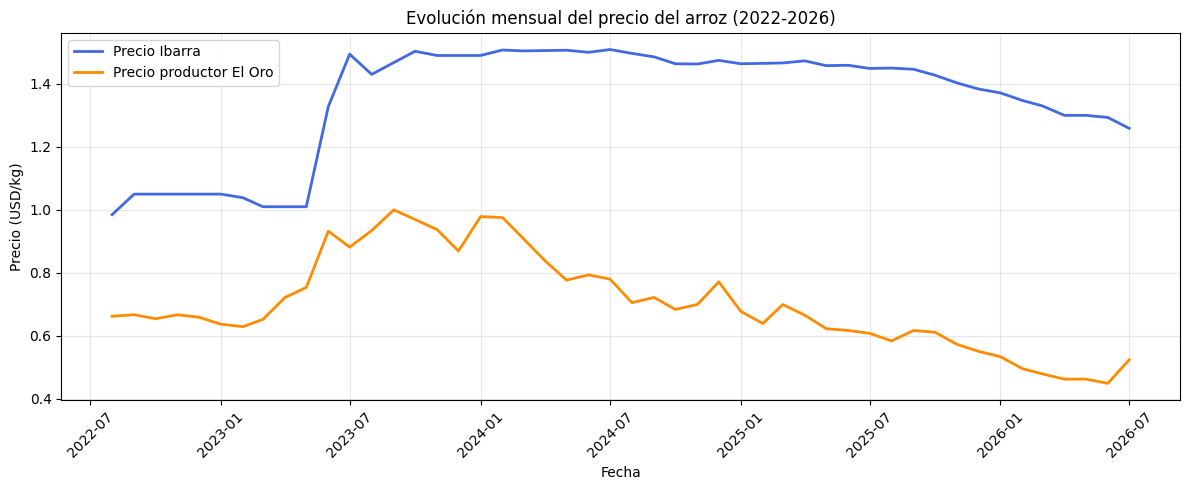

Gráfico generado y guardado correctamente


In [66]:
# PASO 15: Evolución histórica de precios

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    base_integrada["Fecha"],
    base_integrada["Precio_Ibarra"],
    label="Precio Ibarra",
    color="royalblue",
    linewidth=2
)

plt.plot(
    base_integrada["Fecha"],
    base_integrada["Precio_El_Oro"],
    label="Precio productor El Oro",
    color="darkorange",
    linewidth=2
)

plt.title("Evolución mensual del precio del arroz (2022-2026)")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD/kg)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Guardamos el gráfico para GitHub
plt.savefig("01_evolucion_precios_arroz.png", dpi=300)

plt.show()

print("Gráfico generado y guardado correctamente")


Paso 16. Entrenamiento de modelos de regresión Ridge

Se entrenan dos modelos supervisados mediante Ridge Regression de Scikit-learn.

El modelo A utiliza exclusivamente información histórica del precio del arroz en Ibarra.

El modelo B incorpora adicionalmente los precios históricos al productor de El Oro.

El objetivo consiste en evaluar si la información al productor aporta capacidad predictiva adicional para estimar el precio del arroz en Ibarra durante el siguiente mes.

Las variables predictoras se estandarizan utilizando únicamente los datos de entrenamiento, para evitar fugas de información hacia el conjunto de prueba.

In [67]:
# PASO 16: Entrenamiento de modelos Ridge

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Modelo A: solamente precios de Ibarra
modelo_ridge_A = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

modelo_ridge_A.fit(X_train_A, y_train)

# Modelo B: Ibarra y productor El Oro
modelo_ridge_B = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

modelo_ridge_B.fit(X_train_B, y_train)

# Predicciones sobre los datos de prueba
pred_ridge_A = modelo_ridge_A.predict(X_test_A)
pred_ridge_B = modelo_ridge_B.predict(X_test_B)

print("Modelos Ridge entrenados correctamente")

print("\nPrimeras predicciones del modelo A:")
print(pred_ridge_A[:5])

print("\nPrimeras predicciones del modelo B:")
print(pred_ridge_B[:5])


Modelos Ridge entrenados correctamente

Primeras predicciones del modelo A:
[1.43168151 1.41096068 1.39487283 1.38373627 1.36154337]

Primeras predicciones del modelo B:
[1.41230027 1.38051825 1.36448662 1.35118041 1.32056234]


In [68]:
# PASO 17: Evaluación de los modelos predictivos

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Modelo de referencia: persistencia
pred_persistencia = test["Precio_Ibarra"].values

# Función para calcular las métricas
def evaluar_modelo(nombre, reales, predicciones):
    mae = mean_absolute_error(reales, predicciones)
    rmse = np.sqrt(mean_squared_error(reales, predicciones))
    r2 = r2_score(reales, predicciones)

    return {
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

# Evaluamos nuestros tres modelos
resultados = [
    evaluar_modelo("Persistencia", y_test, pred_persistencia),
    evaluar_modelo("Ridge A - Ibarra", y_test, pred_ridge_A),
    evaluar_modelo("Ridge B - Ibarra y El Oro", y_test, pred_ridge_B)
]

# Tabla de resultados
tabla_metricas = pd.DataFrame(resultados)

# Ordenamos por el menor error
tabla_metricas = tabla_metricas.sort_values("MAE")

print("RESULTADOS DE LA EVALUACIÓN:")
display(tabla_metricas.round(4))


RESULTADOS DE LA EVALUACIÓN:


,Modelo,MAE,RMSE,R2
2,Ridge B - Ibarra y El Oro,0.0091,0.0102,0.9493
0,Persistencia,0.0187,0.0215,0.7745
1,Ridge A - Ibarra,0.0334,0.0350,0.3986


Paso 18. Comparación gráfica del desempeño predictivo
Se comparan los errores absolutos medios (MAE) de los modelos Ridge A, Ridge B y persistencia.
Esta visualización permite identificar qué modelo obtuvo menores errores en el conjunto de prueba y evaluar si la incorporación de precios al productor mejora la capacidad predictiva.
Los resultados corresponden a nueve observaciones temporales reservadas para evaluación.

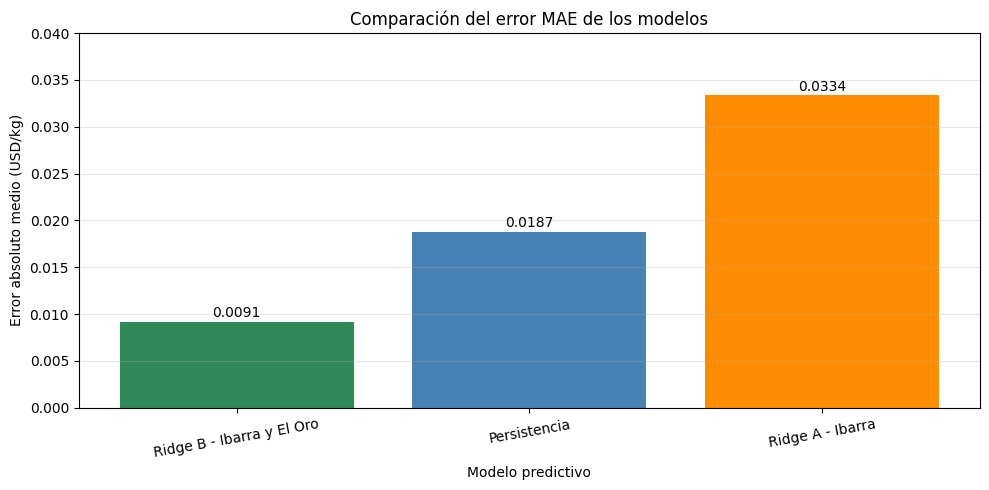

Gráfico de comparación guardado correctamente


In [69]:
# PASO 18: Gráfico comparativo de errores

import matplotlib.pyplot as plt

comparacion = tabla_metricas.sort_values("MAE")

plt.figure(figsize=(10, 5))

barras = plt.bar(
    comparacion["Modelo"],
    comparacion["MAE"],
    color=["seagreen", "steelblue", "darkorange"]
)

# Mostramos los valores encima de las barras
for barra in barras:
    valor = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width()/2,
        valor + 0.0005,
        f"{valor:.4f}",
        ha="center"
    )

plt.title("Comparación del error MAE de los modelos")
plt.ylabel("Error absoluto medio (USD/kg)")
plt.xlabel("Modelo predictivo")
plt.xticks(rotation=10)
plt.ylim(0, comparacion["MAE"].max() * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "02_comparacion_mae_modelos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico de comparación guardado correctamente")


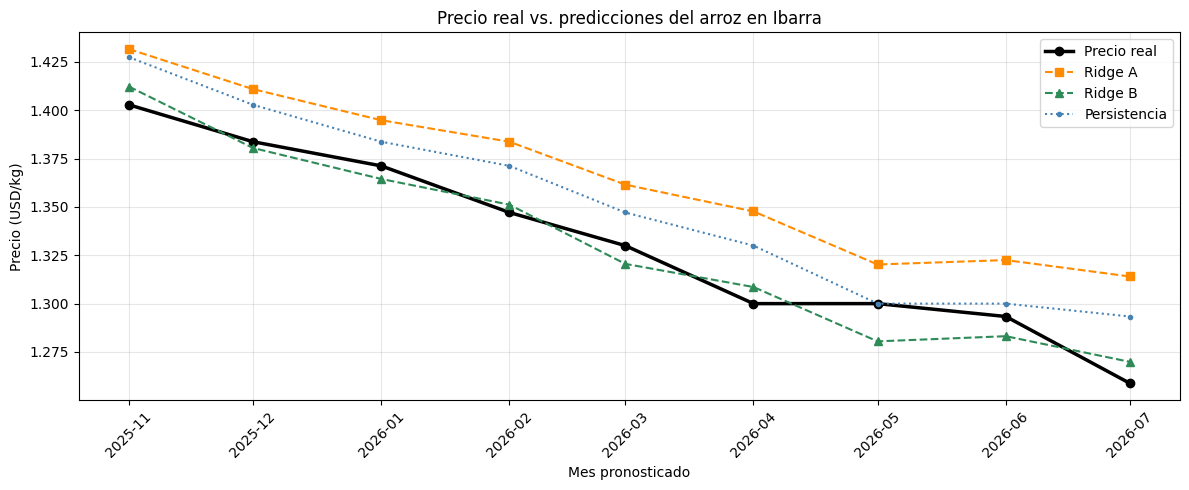

In [70]:
# PASO 19: Precios reales frente a predicciones

# Cada fila predice el precio del mes siguiente
fechas_prediccion = (
    test["Fecha"] + pd.DateOffset(months=1)
)

plt.figure(figsize=(12, 5))

plt.plot(
    fechas_prediccion,
    y_test,
    marker="o",
    linewidth=2.5,
    label="Precio real",
    color="black"
)

plt.plot(
    fechas_prediccion,
    pred_ridge_A,
    marker="s",
    linestyle="--",
    label="Ridge A",
    color="darkorange"
)

plt.plot(
    fechas_prediccion,
    pred_ridge_B,
    marker="^",
    linestyle="--",
    label="Ridge B",
    color="seagreen"
)

plt.plot(
    fechas_prediccion,
    pred_persistencia,
    marker=".",
    linestyle=":",
    label="Persistencia",
    color="steelblue"
)

plt.title("Precio real vs. predicciones del arroz en Ibarra")
plt.xlabel("Mes pronosticado")
plt.ylabel("Precio (USD/kg)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "03_precio_real_vs_predicciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Paso 20. Entrenamiento de modelos Random Forest

Con el propósito de comparar el desempeño de un modelo lineal con un modelo no lineal, se entrenan dos algoritmos de Random Forest Regressor.

El modelo A utiliza únicamente información histórica de Ibarra.

El modelo B incorpora además precios al productor de El Oro.

Debido al tamaño reducido de la muestra, se utiliza una configuración moderada del modelo para reducir el riesgo de sobreajuste.

In [71]:
# PASO 20: Entrenamiento de modelos Random Forest

from sklearn.ensemble import RandomForestRegressor

# Modelo A: solo Ibarra
modelo_rf_A = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    random_state=42
)

modelo_rf_A.fit(X_train_A, y_train)
pred_rf_A = modelo_rf_A.predict(X_test_A)

# Modelo B: Ibarra + El Oro
modelo_rf_B = RandomForestRegressor(
    n_estimators=200,
    max_depth=4,
    random_state=42
)

modelo_rf_B.fit(X_train_B, y_train)
pred_rf_B = modelo_rf_B.predict(X_test_B)

print("Modelos Random Forest entrenados correctamente")

print("\nPrimeras predicciones Random Forest A:")
print(pred_rf_A[:5])

print("\nPrimeras predicciones Random Forest B:")
print(pred_rf_B[:5])

Modelos Random Forest entrenados correctamente

Primeras predicciones Random Forest A:
[1.44141515 1.44929277 1.45764198 1.46105651 1.46087969]

Primeras predicciones Random Forest B:
[1.44015494 1.44018742 1.43900667 1.43894294 1.43878992]


In [72]:
# PASO 21: Evaluación conjunta de todos los modelos

resultados_totales = [
    evaluar_modelo("Persistencia", y_test, pred_persistencia),
    evaluar_modelo("Ridge A - Ibarra", y_test, pred_ridge_A),
    evaluar_modelo("Ridge B - Ibarra y El Oro", y_test, pred_ridge_B),
    evaluar_modelo("RF A - Ibarra", y_test, pred_rf_A),
    evaluar_modelo("RF B - Ibarra y El Oro", y_test, pred_rf_B)
]

tabla_metricas_total = pd.DataFrame(resultados_totales)
tabla_metricas_total = tabla_metricas_total.sort_values("MAE")

print("COMPARACIÓN TOTAL DE MODELOS:")
display(tabla_metricas_total.round(4))

COMPARACIÓN TOTAL DE MODELOS:


,Modelo,MAE,RMSE,R2
2,Ridge B - Ibarra y El Oro,0.0091,0.0102,0.9493
0,Persistencia,0.0187,0.0215,0.7745
1,Ridge A - Ibarra,0.0334,0.0350,0.3986
4,RF B - Ibarra y El Oro,0.1072,0.1162,-5.6115
3,RF A - Ibarra,0.1252,0.1350,-7.9246


Paso 22. Comparación general de los modelos predictivos

Se comparan cinco enfoques de predicción: persistencia, Ridge A, Ridge B, Random Forest A y Random Forest B.

El propósito es identificar las diferencias en el desempeño predictivo utilizando el error absoluto medio (MAE).

Los resultados corresponden al conjunto de prueba de nueve meses. Posteriormente se realizará validación temporal para comprobar la estabilidad de los resultados.

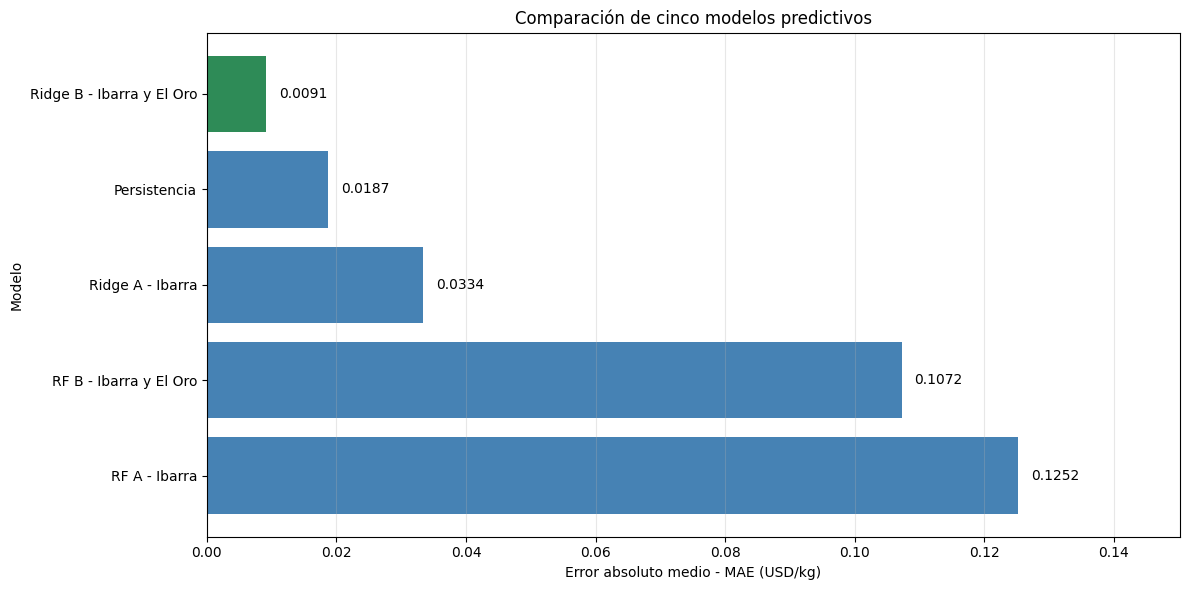

Gráfico de los cinco modelos guardado correctamente


In [73]:
# PASO 22: Gráfico general de comparación de modelos

import matplotlib.pyplot as plt

comparacion_total = tabla_metricas_total.sort_values("MAE")

plt.figure(figsize=(12, 6))

colores = [
    "seagreen" if "Ridge B" in nombre else "steelblue"
    for nombre in comparacion_total["Modelo"]
]

barras = plt.barh(
    comparacion_total["Modelo"],
    comparacion_total["MAE"],
    color=colores
)

# Mostramos el error al lado de cada barra
for barra in barras:
    valor = barra.get_width()
    plt.text(
        valor + 0.002,
        barra.get_y() + barra.get_height()/2,
        f"{valor:.4f}",
        va="center"
    )

plt.title("Comparación de cinco modelos predictivos")
plt.xlabel("Error absoluto medio - MAE (USD/kg)")
plt.ylabel("Modelo")
plt.gca().invert_yaxis()
plt.xlim(0, comparacion_total["MAE"].max() * 1.2)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "04_comparacion_cinco_modelos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico de los cinco modelos guardado correctamente")


## Paso 23. Validación temporal con ventana expansiva

Se aplica validación temporal para evaluar la estabilidad de los modelos predictivos en diferentes períodos históricos.

La validación se realiza exclusivamente dentro de los primeros 36 registros, reservando los últimos nueve como conjunto de prueba final.

En cada iteración, el modelo se entrena con observaciones anteriores y se evalúa con tres observaciones posteriores.

Se comparan los modelos de persistencia, Ridge A, Ridge B, Random Forest A y Random Forest B mediante el error absoluto medio (MAE).

In [74]:
# PASO 23: Validación temporal con ventana expansiva

from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

# Solo utilizamos los 36 registros de entrenamiento
datos_validacion = train.copy()

# Cuatro divisiones temporales con 3 meses de validación
tscv = TimeSeriesSplit(n_splits=4, test_size=3)

modelos_validacion = {
    "Ridge A": (modelo_ridge_A, variables_A),
    "Ridge B": (modelo_ridge_B, variables_B),
    "Random Forest A": (modelo_rf_A, variables_A),
    "Random Forest B": (modelo_rf_B, variables_B)
}

resultados_validacion = []

for numero, (idx_entreno, idx_val) in enumerate(
    tscv.split(datos_validacion), start=1
):
    entreno_temporal = datos_validacion.iloc[idx_entreno]
    validacion_temporal = datos_validacion.iloc[idx_val]

    y_val = validacion_temporal[objetivo]

    # Modelo de persistencia
    pred_base = validacion_temporal["Precio_Ibarra"]

    resultados_validacion.append({
        "Ventana": numero,
        "Modelo": "Persistencia",
        "MAE": mean_absolute_error(y_val, pred_base)
    })

    # Modelos de Machine Learning
    for nombre, (modelo, variables) in modelos_validacion.items():

        modelo_temporal = clone(modelo)

        modelo_temporal.fit(
            entreno_temporal[variables],
            entreno_temporal[objetivo]
        )

        predicciones = modelo_temporal.predict(
            validacion_temporal[variables]
        )

        resultados_validacion.append({
            "Ventana": numero,
            "Modelo": nombre,
            "MAE": mean_absolute_error(y_val, predicciones)
        })

tabla_validacion = pd.DataFrame(resultados_validacion)

print("RESULTADOS DE VALIDACIÓN TEMPORAL:")
display(tabla_validacion.round(4))

print("\nMAE PROMEDIO POR MODELO:")
resumen_validacion = (
    tabla_validacion
    .groupby("Modelo")["MAE"]
    .agg(["mean", "std"])
    .sort_values("mean")
)

display(resumen_validacion.round(4))


RESULTADOS DE VALIDACIÓN TEMPORAL:


,Ventana,Modelo,MAE
0,1,Persistencia,0.0077
1,1,Ridge A,0.0081
2,1,Ridge B,0.0445
3,1,Random Forest A,0.0278
4,1,Random Forest B,0.1264
5,2,Persistencia,0.0030
6,2,Ridge A,0.0023
7,2,Ridge B,0.0493
8,2,Random Forest A,0.0038
9,2,Random Forest B,0.1553



MAE PROMEDIO POR MODELO:


,mean,std
Modelo,,
Persistencia,0.0068,0.0026
Ridge A,0.0079,0.0040
Random Forest A,0.0160,0.0098
Ridge B,0.0356,0.0137
Random Forest B,0.0988,0.0636


##Paso 24. Análisis gráfico de la validación temporal
Se visualiza el error absoluto medio de los modelos predictivos en cuatro ventanas de validación cronológica.
El objetivo es analizar cómo cambia el desempeño de los modelos según el período evaluado, identificar posibles diferencias de estabilidad y contrastar los resultados con la evaluación final de nueve meses.
Se mantiene el conjunto de prueba final separado de este procedimiento.

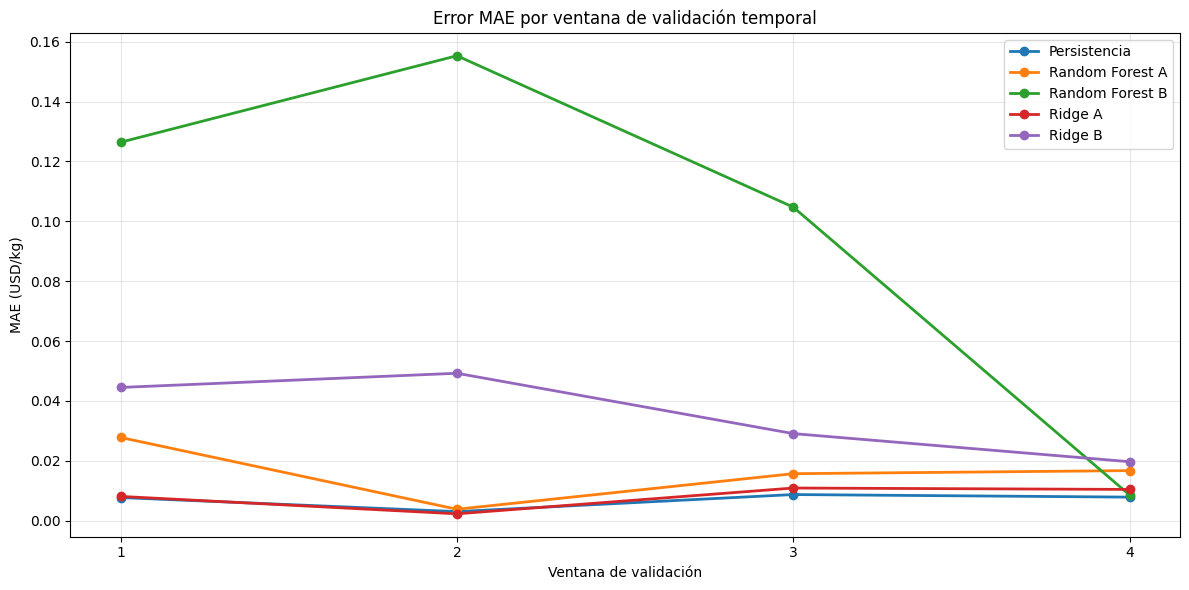

Gráfico de validación temporal guardado


In [75]:
# PASO 24: Visualización de la validación temporal

import matplotlib.pyplot as plt

# Organizamos los resultados por ventana y modelo
grafico_validacion = tabla_validacion.pivot(
    index="Ventana",
    columns="Modelo",
    values="MAE"
)

plt.figure(figsize=(12, 6))

for modelo in grafico_validacion.columns:
    plt.plot(
        grafico_validacion.index,
        grafico_validacion[modelo],
        marker="o",
        linewidth=2,
        label=modelo
    )

plt.title("Error MAE por ventana de validación temporal")
plt.xlabel("Ventana de validación")
plt.ylabel("MAE (USD/kg)")
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "05_validacion_temporal_modelos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico de validación temporal guardado")


## Paso 25. Identificación de los períodos de validación

Se identifican las fechas correspondientes a cada ventana de validación temporal para interpretar las diferencias de desempeño de los modelos según el período histórico evaluado.

Este análisis permite contextualizar los errores obtenidos y verificar que las observaciones utilizadas para entrenar sean anteriores a las observaciones evaluadas.
 Copiar texto

In [76]:
# PASO 25: Identificar períodos de validación

periodos = []

for numero, (idx_entreno, idx_val) in enumerate(
    tscv.split(datos_validacion), start=1
):
    entreno = datos_validacion.iloc[idx_entreno]
    validacion = datos_validacion.iloc[idx_val]

    periodos.append({
        "Ventana": numero,
        "Fin_entrenamiento": entreno["Fecha"].max(),
        "Primer_mes_validacion": validacion["Fecha"].min(),
        "Ultimo_mes_validacion": validacion["Fecha"].max(),
        "Meses_entrenamiento": len(entreno),
        "Meses_validacion": len(validacion)
    })

tabla_periodos = pd.DataFrame(periodos)

print("PERÍODOS DE VALIDACIÓN TEMPORAL:")
display(tabla_periodos)


PERÍODOS DE VALIDACIÓN TEMPORAL:


,Ventana,Fin_entrenamiento,Primer_mes_validacion,Ultimo_mes_validacion,Meses_entrenamiento,Meses_validacion
0,1,2024-09-01,2024-10-01,2024-12-01,24,3
1,2,2024-12-01,2025-01-01,2025-03-01,27,3
2,3,2025-03-01,2025-04-01,2025-06-01,30,3
3,4,2025-06-01,2025-07-01,2025-09-01,33,3


## Paso 26. Preparación del pronóstico de agosto de 2026

Se construye el registro de entrada correspondiente a julio de 2026 utilizando los últimos precios disponibles de Ibarra y El Oro, así como sus rezagos históricos.

El objetivo es estimar el precio del arroz en Ibarra para agosto de 2026, mes que se encuentra fuera del período observado en la base utilizada.

El pronóstico se presentará como una estimación retrospectiva y se contrastará con el modelo de persistencia.
 Copiar texto

In [77]:
# PASO 26: Preparar los datos del mes de julio de 2026

# Trabajamos con la base mensual original
base_ordenada = base_integrada.sort_values("Fecha").copy()

# Obtenemos los últimos tres meses
ultimos_meses = base_ordenada.tail(3)

print("ÚLTIMOS TRES MESES DISPONIBLES:")
display(
    ultimos_meses[
        ["Fecha", "Precio_Ibarra", "Precio_El_Oro"]
    ]
)

# Construimos las variables para agosto de 2026
datos_agosto = pd.DataFrame([{
    "Precio_Ibarra": base_ordenada["Precio_Ibarra"].iloc[-1],
    "Ibarra_mes_anterior": base_ordenada["Precio_Ibarra"].iloc[-2],
    "Ibarra_dos_meses": base_ordenada["Precio_Ibarra"].iloc[-3],
    "Precio_El_Oro": base_ordenada["Precio_El_Oro"].iloc[-1],
    "El_Oro_mes_anterior": base_ordenada["Precio_El_Oro"].iloc[-2]
}])

print("\nVARIABLES PREPARADAS PARA EL PRONÓSTICO:")
display(datos_agosto)


ÚLTIMOS TRES MESES DISPONIBLES:


,Fecha,Precio_Ibarra,Precio_El_Oro
45,2026-05-01,1.300000,0.462971
46,2026-06-01,1.293333,0.449404
47,2026-07-01,1.258750,0.524131



VARIABLES PREPARADAS PARA EL PRONÓSTICO:


,Precio_Ibarra,Ibarra_mes_anterior,Ibarra_dos_meses,Precio_El_Oro,El_Oro_mes_anterior
0,1.25875,1.293333,1.3,0.524131,0.449404


## Paso 27. Pronóstico del precio del arroz para agosto de 2026

Se reentrena el modelo Ridge B utilizando las 45 observaciones históricas disponibles para aprendizaje supervisado.

Posteriormente se utiliza la información conocida hasta julio de 2026 para estimar el precio del arroz en Ibarra correspondiente a agosto de 2026.

El resultado se compara con el modelo de persistencia, que supone que el precio del siguiente mes será igual al último observado.

Esta estimación es retrospectiva, dado que agosto de 2026 ya transcurrió.

In [78]:
# PASO 27: Predicción final con Ridge B

from sklearn.base import clone

# Reentrenamos con todos los datos supervisados
modelo_final = clone(modelo_ridge_B)

modelo_final.fit(
    datos_ml[variables_B],
    datos_ml["Precio_siguiente_mes"]
)

# Generamos el pronóstico para agosto de 2026
precio_predicho = modelo_final.predict(
    datos_agosto[variables_B]
)[0]

# Modelo de persistencia
precio_persistencia = datos_agosto["Precio_Ibarra"].iloc[0]

# Calculamos la variación estimada
variacion = (
    (precio_predicho - precio_persistencia)
    / precio_persistencia
) * 100

print("PRONÓSTICO PARA AGOSTO DE 2026")
print(f"Último precio observado: ${precio_persistencia:.4f}/kg")
print(f"Predicción Ridge B: ${precio_predicho:.4f}/kg")
print(f"Predicción persistencia: ${precio_persistencia:.4f}/kg")
print(f"Variación estimada: {variacion:.2f}%")


PRONÓSTICO PARA AGOSTO DE 2026
Último precio observado: $1.2587/kg
Predicción Ridge B: $1.2697/kg
Predicción persistencia: $1.2587/kg
Variación estimada: 0.87%


##Paso 28. Visualización del pronóstico del precio del arroz
Se presenta la evolución observada del precio del arroz en Ibarra y el pronóstico retrospectivo correspondiente a agosto de 2026.
La estimación se obtiene mediante el modelo Ridge B, entrenado con precios históricos de Ibarra y El Oro.
El gráfico distingue los valores realmente observados de las estimaciones generadas por Machine Learning. También se incorpora el pronóstico de persistencia como referencia.

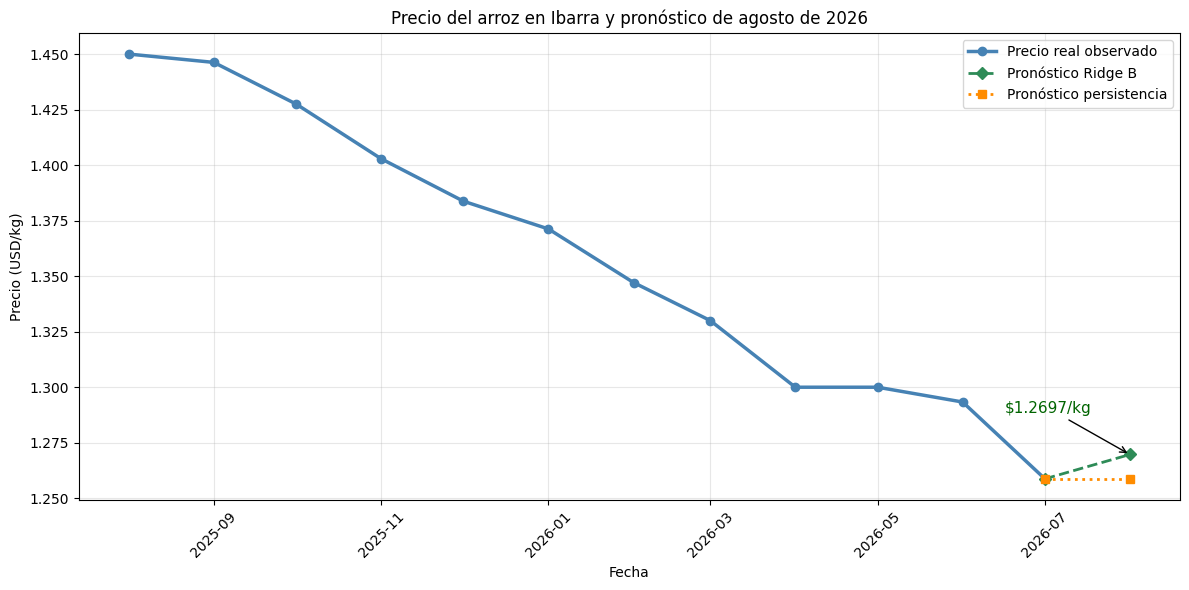

Gráfico de pronóstico guardado correctamente


In [79]:
# PASO 28: Gráfico del pronóstico de agosto de 2026

import matplotlib.pyplot as plt
import pandas as pd

# Seleccionamos los últimos 12 meses observados
historico = base_integrada.sort_values("Fecha").tail(12)

# Definimos la fecha pronosticada
fecha_pronostico = pd.Timestamp("2026-08-01")

plt.figure(figsize=(12, 6))

# Serie histórica observada
plt.plot(
    historico["Fecha"],
    historico["Precio_Ibarra"],
    marker="o",
    linewidth=2.5,
    color="steelblue",
    label="Precio real observado"
)

# Último precio real
ultima_fecha = historico["Fecha"].iloc[-1]
ultimo_precio = historico["Precio_Ibarra"].iloc[-1]

# Predicción de Ridge B
plt.plot(
    [ultima_fecha, fecha_pronostico],
    [ultimo_precio, precio_predicho],
    marker="D",
    linestyle="--",
    linewidth=2,
    color="seagreen",
    label="Pronóstico Ridge B"
)

# Predicción de persistencia
plt.plot(
    [ultima_fecha, fecha_pronostico],
    [ultimo_precio, precio_persistencia],
    marker="s",
    linestyle=":",
    linewidth=2,
    color="darkorange",
    label="Pronóstico persistencia"
)

# Etiqueta del precio pronosticado
plt.annotate(
    f"${precio_predicho:.4f}/kg",
    xy=(fecha_pronostico, precio_predicho),
    xytext=(-90, 30),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->"},
    color="darkgreen",
    fontsize=11
)

plt.title(
    "Precio del arroz en Ibarra y pronóstico de agosto de 2026"
)
plt.xlabel("Fecha")
plt.ylabel("Precio (USD/kg)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Guardamos el gráfico para GitHub
plt.savefig(
    "06_pronostico_arroz_agosto_2026.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico de pronóstico guardado correctamente")


## Paso 29. Evaluación de alzas y bajas del precio del arroz

Se analiza si las predicciones de Ridge B permiten identificar correctamente la dirección de los cambios mensuales del precio del arroz.

Se comparan las variaciones reales y estimadas respecto al precio del mes anterior, clasificándolas como alza, baja o estabilidad.

Este procedimiento es una evaluación de la dirección derivada de un modelo de regresión, no un clasificador entrenado independientemente.
 Copiar texto

In [80]:
# PASO 29: Evaluar alzas y bajas con Ridge B

import numpy as np
import pandas as pd

# Precios conocidos al momento de predecir
precio_actual = test["Precio_Ibarra"].to_numpy()

# Calculamos los cambios reales y estimados
cambio_real = y_test.to_numpy() - precio_actual
cambio_predicho = pred_ridge_B - precio_actual

# Definimos las categorías de cambio
def clasificar_cambio(cambio, tolerancia=0.001):
    return np.where(
        cambio > tolerancia,
        "Alza",
        np.where(
            cambio < -tolerancia,
            "Baja",
            "Estable"
        )
    )

direccion_real = clasificar_cambio(cambio_real)
direccion_predicha = clasificar_cambio(cambio_predicho)

# Calculamos correctamente el mes pronosticado
fechas_prediccion = (
    test["Fecha"] + pd.DateOffset(months=1)
).to_numpy()

# Construimos la tabla comparativa
tabla_direccion = pd.DataFrame({
    "Mes": fechas_prediccion,
    "Precio_real": y_test.to_numpy(),
    "Precio_predicho": pred_ridge_B,
    "Direccion_real": direccion_real,
    "Direccion_predicha": direccion_predicha
})

# Identificamos los aciertos
tabla_direccion["Acierto"] = (
    tabla_direccion["Direccion_real"]
    == tabla_direccion["Direccion_predicha"]
)

print("RESULTADOS DE ALZAS Y BAJAS:")
display(tabla_direccion.round(4))

# Calculamos el porcentaje de aciertos
acierto_porcentaje = (
    tabla_direccion["Acierto"].mean() * 100
)

print("\nACIERTO EN LA DIRECCIÓN:")
print(f"{acierto_porcentaje:.2f}%")


RESULTADOS DE ALZAS Y BAJAS:


,Mes,Precio_real,Precio_predicho,Direccion_real,Direccion_predicha,Acierto
0,2025-11-01,1.4029,1.4123,Baja,Baja,True
1,2025-12-01,1.3838,1.3805,Baja,Baja,True
2,2026-01-01,1.3712,1.3645,Baja,Baja,True
3,2026-02-01,1.3471,1.3512,Baja,Baja,True
4,2026-03-01,1.3300,1.3206,Baja,Baja,True
5,2026-04-01,1.3000,1.3086,Baja,Baja,True
6,2026-05-01,1.3000,1.2805,Estable,Baja,False
7,2026-06-01,1.2933,1.2831,Baja,Baja,True
8,2026-07-01,1.2587,1.2699,Baja,Baja,True



ACIERTO EN LA DIRECCIÓN:
88.89%


##Paso 30. Comparación de la dirección predicha con una referencia básica

Se evalúa el porcentaje de aciertos de Ridge B frente a un modelo de referencia que predice siempre una disminución del precio.

El objetivo es determinar si el porcentaje de clasificación obtenido aporta información adicional o se explica principalmente por el predominio de meses con precios descendentes.

Este análisis complementa la evaluación de regresión y permite identificar limitaciones en la predicción de alzas y bajas.

In [81]:
# PASO 30: Comparación de clasificación con referencia

from sklearn.metrics import accuracy_score, confusion_matrix

# Predicción de referencia: siempre baja
prediccion_referencia = np.array(
    ["Baja"] * len(direccion_real)
)

# Calculamos los porcentajes de acierto
acierto_ridge = accuracy_score(
    direccion_real, direccion_predicha
)

acierto_referencia = accuracy_score(
    direccion_real, prediccion_referencia
)

print("COMPARACIÓN DE ACIERTOS:")
print(f"Ridge B: {acierto_ridge * 100:.2f}%")
print(f"Siempre Baja: {acierto_referencia * 100:.2f}%")

# Matriz de confusión
categorias = ["Alza", "Baja", "Estable"]

matriz = confusion_matrix(
    direccion_real,
    direccion_predicha,
    labels=categorias
)

print("\nMATRIZ DE CONFUSIÓN:")
display(
    pd.DataFrame(
        matriz,
        index=[f"Real_{c}" for c in categorias],
        columns=[f"Predicha_{c}" for c in categorias]
    )
)


COMPARACIÓN DE ACIERTOS:
Ridge B: 88.89%
Siempre Baja: 88.89%

MATRIZ DE CONFUSIÓN:


,Predicha_Alza,Predicha_Baja,Predicha_Estable
Real_Alza,0,0,0
Real_Baja,0,8,0
Real_Estable,0,1,0


##Paso 31. Visualización de la matriz de confusión

Se representa gráficamente la coincidencia entre las direcciones reales y estimadas del precio del arroz mediante Ridge B.

La matriz permite identificar aciertos y errores en las categorías alza, baja y estabilidad.

El análisis se considera complementario a la regresión, dado que el conjunto de prueba no contiene ejemplos de incrementos y presenta un predominio de disminuciones.

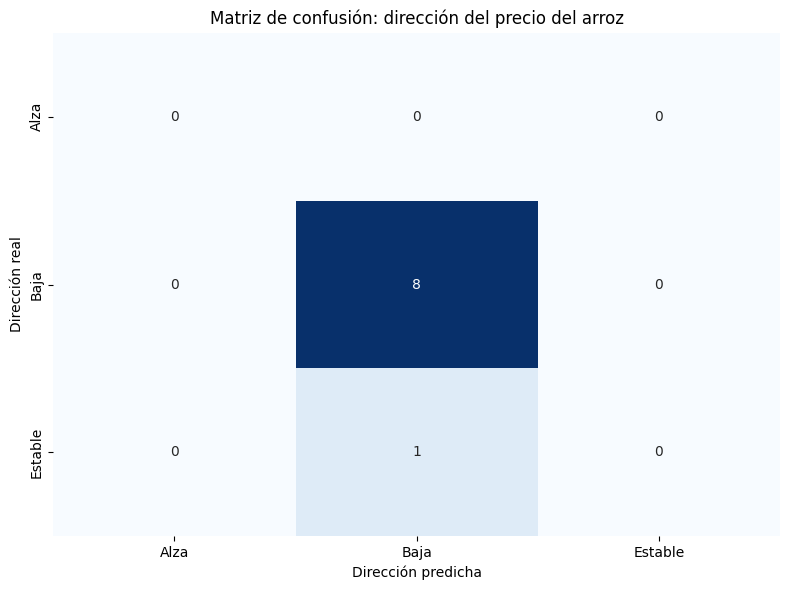

Matriz de confusión guardada correctamente


In [82]:
# PASO 31: Matriz de confusión visual

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=categorias,
    yticklabels=categorias,
    cbar=False
)

plt.title("Matriz de confusión: dirección del precio del arroz")
plt.xlabel("Dirección predicha")
plt.ylabel("Dirección real")
plt.tight_layout()

plt.savefig(
    "07_matriz_confusion_alzas_bajas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Matriz de confusión guardada correctamente")


In [83]:
# PASO 32: Guardar la base integrada

base_integrada.to_csv(
    "base_arroz_integrada.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Base integrada guardada correctamente")


Base integrada guardada correctamente


In [84]:
# PASO 32.1: Descargar resultados para GitHub

import os
import zipfile
from google.colab import files

archivos_proyecto = [
    "base_arroz_integrada.csv",
    "01_evolucion_precios_arroz.png",
    "02_comparacion_mae_modelos.png",
    "03_precio_real_vs_predicciones.png",
    "04_comparacion_cinco_modelos.png",
    "05_validacion_temporal_modelos.png",
    "06_pronostico_arroz_agosto_2026.png",
    "07_matriz_confusion_alzas_bajas.png"
]

with zipfile.ZipFile(
    "resultados_arroz_github.zip", "w"
) as zipf:
    for archivo in archivos_proyecto:
        if os.path.exists(archivo):
            zipf.write(archivo)
            print("Incluido:", archivo)
        else:
            print("No encontrado:", archivo)

files.download("resultados_arroz_github.zip")


Incluido: base_arroz_integrada.csv
Incluido: 01_evolucion_precios_arroz.png
Incluido: 02_comparacion_mae_modelos.png
Incluido: 03_precio_real_vs_predicciones.png
Incluido: 04_comparacion_cinco_modelos.png
Incluido: 05_validacion_temporal_modelos.png
Incluido: 06_pronostico_arroz_agosto_2026.png
Incluido: 07_matriz_confusion_alzas_bajas.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>